## 1. Experiment design

### 1.1 What was manipulated?
Dekker, Luberti and Stam (2023) randomly offered 255 students access to weekly, 100-minute peer-led study sessions for seven weeks. The 238 controls received usual instruction and could attend SI in the following quarter. Trained students led collaborative practice of material already taught. More time on task and discussion could improve grades; repeated contact and mutual support could improve well-being and belonging. The treatment is **access to SI**, not attendance: 29% of those invited never attended. Comparing attendees with non-attendees would bring self-selection back into the analysis.

### 1.2 Concepts and measures
**Academic performance:** administrative examination grades, from 0 to 10, with 5.5 required to pass. These are consequential and avoid self-report bias, but examinations may capture short-term preparation better than durable learning. Grades may also be difficult to compare across subjects.

**Mental well-being:** the Dutch Short Warwick-Edinburgh scale, measured before and after the intervention. The paper describes seven items on a five-point frequency scale covering the previous two weeks, with reliability of 0.77 and 0.75. The scale covers feeling good and functioning well, but general well-being may miss course-specific anxiety or longer-term benefits.

**Belonging:** a six-item, five-point scale covering inclusion in the college community, including feeling at home and avoiding classes (reverse-coded). Reliability was 0.68 at baseline and 0.65 at follow-up. This is a relevant measure, but institutional belonging may change less quickly than relationships within a study group, and measurement noise can obscure an effect. The released aggregate scores do not allow independent checks of item coding or reliability.

Other useful outcomes would include knowledge retention, transfer to unfamiliar problems, academic self-efficacy and the time burden of attending. Credits and retention are already present in the dataset, so they are not wholly unmeasured outcomes. The paper's measures are described in section 2.3.

### 1.3 Design grammar
Let $O_0$ be baseline well-being and belonging, $X$ the offer of SI and $Y_1$ the post-intervention grade, well-being and belonging outcomes:

| Recruitment | Baseline | Assignment | Intervention | Follow-up |
|---|---|---|---|---|
| $N$ (opt-in) | $O_0$ | $R$ | $X$ | $Y_1$ |
| $N$ (opt-in) | $O_0$ | $R$ | - | $Y_1$ |

$N$ refers to recruitment: 493 of 852 eligible students participated. Treatment assignment was random, after the baseline survey. The preregistration specifies simple individual randomisation, not classroom randomisation. There was no baseline measure of the same examination grade. The lecture's $W$ notation serves the same role as $X$ here.

Random allocation addresses selection into access, and concurrent controls help separate treatment from common changes over the term. Baseline surveys, administrative grades and preregistration strengthen the design. Its limits include missing outcomes, non-attendance, possible spillovers between classmates and a short follow-up. Students could not realistically be blinded to access. Recruitment from one institution also limits generalisation. The registered later crossover is not analysed in the published first-quarter results or supplied data.

## 2. Randomisation inference

### 2.1 Check the supplied data
The processed file contains 414 grades, while the raw file and paper contain 432. Its integer-typed grade column has silently dropped 18 valid decimal grades through the supplied cleaning script's `ignore_errors=True` setting. I retain the supplied-file analysis and compare it with the raw numeric grades. I do not replace missing examinations with zero. All other columns agree.

In [1]:
#| echo: false
from pathlib import Path
import json
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display, Markdown

OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
SEED = 2412026
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#234e70', '#b66b16', '#65794a', '#8b5379', '#555555']

def show_table(table, digits=4):
    readable = table.astype(object).copy()
    for column in table.columns:
        for index, value in table[column].items():
            if pd.isna(value):
                text = '-'
            elif column == 'Exposed':
                text = str(int(value))
            elif isinstance(value, (float, np.floating)):
                text = f'{value:.{digits}f}'
            else:
                text = str(value)
            readable.at[index, column] = text
    display(Markdown(readable.to_markdown(index=False, disable_numparse=True)))

processed_pl = pl.read_parquet('data/processed/supplimental_instruction.parquet')
processed = pd.DataFrame(processed_pl.to_dict(as_series=False))
raw = pd.read_csv('data/raw/SIdataset.csv')
raw.columns = raw.columns.str.lower()
assert len(raw) == len(processed) == 493
assert raw['treatment'].equals(processed['treatment'])
assert raw['group'].equals(processed['group'])
assert raw['course'].equals(processed['course'])
assert raw['treatment'].sum() == 255

lost_decimal = raw['grade'].notna() & processed['grade'].isna()
assert lost_decimal.sum() == 18
assert (raw.loc[lost_decimal, 'grade'] % 1 != 0).all()
assert raw['grade'].notna().sum() == 432
assert processed['grade'].notna().sum() == 414
assert raw['t1_wellbeing'].notna().sum() == 320
assert raw['t1_belong'].notna().sum() == 320
for col in raw.columns.difference(['grade', 'grade_nomiss']):
    pd.testing.assert_series_equal(raw[col], processed[col],
                                   check_dtype=False, check_names=False)

audit = pd.DataFrame({
    'Source/outcome': ['Processed grade', 'Raw grade',
                       'Follow-up well-being', 'Follow-up belonging'],
    'Observed': [414, 432, 320, 320],
    'Missing': [79, 61, 173, 173]})
show_table(audit, 0)
raw.loc[lost_decimal, ['course', 'group', 'treatment', 'grade']].to_csv(
    OUT / '18_decimal_grades_lost_in_processed_file.csv', index=False)

| Source/outcome       | Observed   | Missing   |
|:---------------------|:-----------|:----------|
| Processed grade      | 414        | 79        |
| Raw grade            | 432        | 61        |
| Follow-up well-being | 320        | 173       |
| Follow-up belonging  | 320        | 173       |

### 2.2 Test and results
For each outcome, the sharp null is $Y_i(1)=Y_i(0)$ for every student. The statistic is the difference in observed means, SI minus control. I shuffle the 255 treatment labels across all 493 students, conditional on that total, and recompute the observed-case denominators each time. The two-sided p-value is $(1+\#\{|T_b|\geq|T_{obs}|\})/(B+1)$, using 99,999 draws.

This treats missingness as fixed under reassignment and assumes no interference. If assignment affects examination participation or survey response, the complete-case analysis does not identify an unconditional effect for all students. No demographic or attendance adjustment is used.

In [2]:
def randomisation_inference(y, z, draws=99999, seed=SEED):
    # y has one column per analysis; NaNs remain fixed in every draw.
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=int)
    observed_mask = np.isfinite(y).astype(float)
    values = np.nan_to_num(y, nan=0.0)
    totals = values.sum(axis=0)
    observed_n = observed_mask.sum(axis=0)

    def statistic(assignments):
        nt = assignments @ observed_mask
        nc = observed_n - nt
        st = assignments @ values
        return st / nt - (totals - st) / nc

    actual = statistic(z[None, :])[0]
    rng = np.random.default_rng(seed)
    null = np.empty((draws, y.shape[1]))
    for start in range(0, draws, 1000):
        size = min(1000, draws - start)
        assignments = rng.permuted(np.tile(z, (size, 1)), axis=1)
        assert np.all(assignments.sum(axis=1) == z.sum())
        null[start:start+size] = statistic(assignments)
    extremes = (np.abs(null) >= np.abs(actual) - 1e-12).sum(axis=0)
    p = (extremes + 1) / (draws + 1)
    return actual, p, null

outcomes = np.column_stack([processed['grade'], raw['grade'],
                            raw['t1_wellbeing'], raw['t1_belong']])
z = raw['treatment'].to_numpy()
effects, pvalues, null_draws = randomisation_inference(outcomes, z)
labels = ['Grade: supplied processed', 'Grade: raw corrected',
          'Well-being: follow-up', 'Belonging: follow-up']
rows = []
for j, label in enumerate(labels):
    observed = np.isfinite(outcomes[:, j])
    yt = outcomes[(z == 1) & observed, j]
    yc = outcomes[(z == 0) & observed, j]
    rows.append({'Outcome': label, 'n SI': len(yt), 'n control': len(yc),
                 'Mean SI': yt.mean(), 'Mean control': yc.mean(),
                 'Difference': effects[j], 'RI p': pvalues[j]})
ri_results = pd.DataFrame(rows)
ri_results.to_csv(OUT / 'randomisation_results.csv', index=False)
# Narrow tables remain readable in the PDF.
show_table(ri_results[['Outcome', 'n SI', 'n control', 'Mean SI', 'Mean control']])
show_table(ri_results[['Outcome', 'Difference', 'RI p']])
print('Largest Monte Carlo standard error:',
      round(float(np.sqrt(pvalues * (1-pvalues) / 99999).max()), 5))

| Outcome                   | n SI   | n control   | Mean SI   | Mean control   |
|:--------------------------|:-------|:------------|:----------|:---------------|
| Grade: supplied processed | 217    | 197         | 6.3687    | 6.0508         |
| Grade: raw corrected      | 226    | 206         | 6.3872    | 6.0199         |
| Well-being: follow-up     | 172    | 148         | 3.4535    | 3.5014         |
| Belonging: follow-up      | 172    | 148         | 3.9012    | 3.8649         |

| Outcome                   | Difference   | RI p   |
|:--------------------------|:-------------|:-------|
| Grade: supplied processed | 0.3179       | 0.0946 |
| Grade: raw corrected      | 0.3673       | 0.0482 |
| Well-being: follow-up     | -0.0479      | 0.4312 |
| Belonging: follow-up      | 0.0363       | 0.5879 |

Largest Monte Carlo standard error: 0.00157


| Focal outcome         | Unadjusted RI p   | Holm-adjusted p   |
|:----------------------|:------------------|:------------------|
| Grade: raw corrected  | 0.0482            | 0.1445            |
| Well-being: follow-up | 0.4312            | 0.8623            |
| Belonging: follow-up  | 0.5879            | 0.8623            |

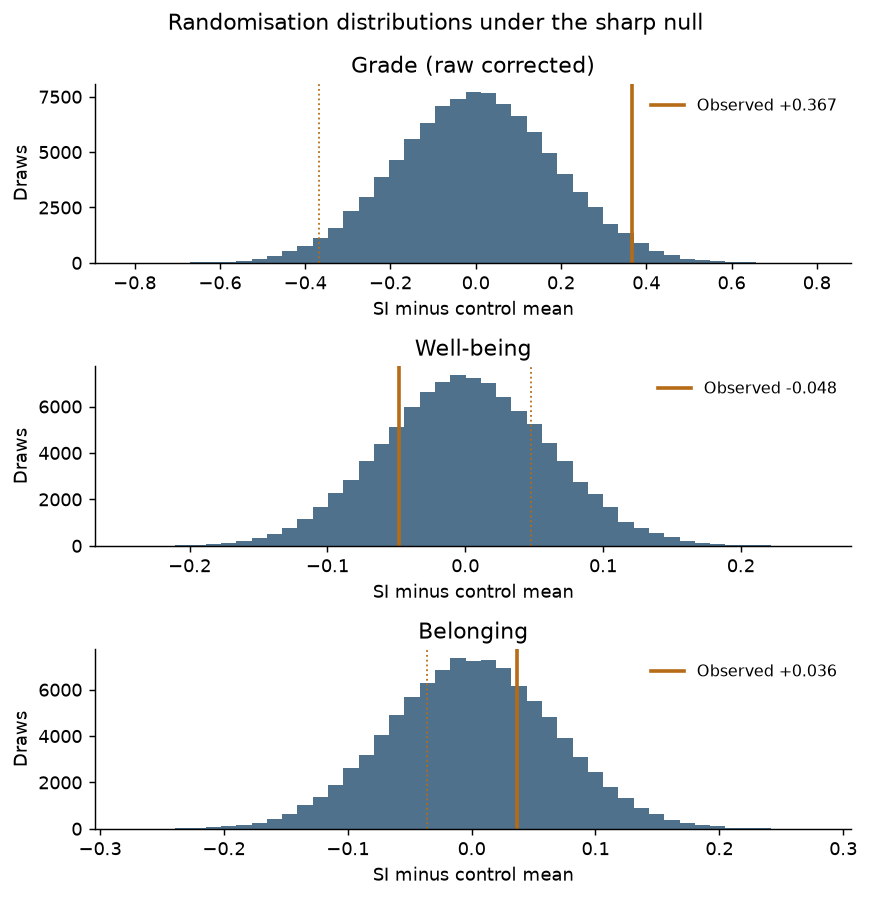

In [3]:
#| echo: false
# A multiplicity sensitivity check for the three corrected focal outcomes.
def holm_adjust(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.minimum(1, np.maximum.accumulate(
        (len(p) - np.arange(len(p))) * p[order]))
    result = np.empty_like(adjusted)
    result[order] = adjusted
    return result

adjusted_p = holm_adjust(pvalues[1:])
show_table(pd.DataFrame({'Focal outcome': labels[1:],
                         'Unadjusted RI p': pvalues[1:],
                         'Holm-adjusted p': adjusted_p}))

fig, axes = plt.subplots(3, 1, figsize=(6.8, 7.0))
for ax, j, title in zip(axes, [1, 2, 3],
                         ['Grade (raw corrected)', 'Well-being', 'Belonging']):
    ax.hist(null_draws[:, j], bins=45, color=COLORS[0], alpha=.8)
    ax.axvline(effects[j], color=COLORS[1], lw=2,
               label=f'Observed {effects[j]:+.3f}')
    ax.axvline(-effects[j], color=COLORS[1], lw=1, ls=':')
    ax.set(title=title, xlabel='SI minus control mean', ylabel='Draws')
    ax.legend(frameon=False, fontsize=9)
fig.suptitle('Randomisation distributions under the sharp null')
fig.tight_layout()
fig.savefig(OUT / 'randomisation_distributions.png', dpi=220)
plt.show()

In [4]:
#| echo: false

display(Markdown(f'''
### 2.3 Interpretation
The corrected mean grade is **{effects[1]:.3f} points higher** in the SI arm
(6.387 versus 6.020; p={pvalues[1]:.4f}). This is borderline evidence at 5%.
The supplied processed file gives {effects[0]:.3f} points and p={pvalues[0]:.4f},
so the cleaning error changes the conclusion. The paper's unadjusted multilevel
model reports 0.43 points and p=0.011; a difference in means with randomisation
inference is a different analysis, not an exact replication of that model.

Well-being differs by {effects[2]:+.3f} (p={pvalues[2]:.4f}) and belonging by
{effects[3]:+.3f} (p={pvalues[3]:.4f}). Neither is statistically detectable,
but this does not establish zero effects. Attrition, scale reliability and
follow-up length matter. If family-wise error is controlled across the three
focal outcomes, the Holm-adjusted grade p-value is {adjusted_p[0]:.4f}.
'''))


### 2.3 Interpretation
The corrected mean grade is **0.367 points higher** in the SI arm
(6.387 versus 6.020; p=0.0482). This is borderline evidence at 5%.
The supplied processed file gives 0.318 points and p=0.0946,
so the cleaning error changes the conclusion. The paper's unadjusted multilevel
model reports 0.43 points and p=0.011; a difference in means with randomisation
inference is a different analysis, not an exact replication of that model.

Well-being differs by -0.048 (p=0.4312) and belonging by
+0.036 (p=0.5879). Neither is statistically detectable,
but this does not establish zero effects. Attrition, scale reliability and
follow-up length matter. If family-wise error is controlled across the three
focal outcomes, the Holm-adjusted grade p-value is 0.1445.


## 3. Power analysis

### 3.1 Assumptions and function
Everyone receives the ordinary email. $C$ denotes email only, $B$ adds bCourses and $F$ adds flyers. I assume independent binary attendance, 40% baseline turnout, a maximum of 2,000 participants and an 80% power target. The plots use differences of 2, 5, 8, 10 and 15 **percentage points**. These are planning assumptions, not measured effects.

For arm sizes $n_j$, probabilities $p_j$ and contrast weights $c_j$, let $\Delta=\sum c_jp_j$ and $V=\sum c_j^2p_j(1-p_j)/n_j$. Approximate two-sided Wald-test power is

$$\Phi(-z_{1-\alpha/2}-\Delta/\sqrt V)+1-\Phi(z_{1-\alpha/2}-\Delta/\sqrt V).$$

In [5]:
def allocation(total, shares):
    shares = np.asarray(shares, dtype=float)
    expected = total * shares / shares.sum()
    counts = np.floor(expected).astype(int)
    for j in np.argsort(-(expected - counts))[:total-counts.sum()]:
        counts[j] += 1
    return counts

def contrast_power(counts, probabilities, contrast, alpha=.05):
    counts = np.asarray(counts, dtype=float)
    probabilities = np.asarray(probabilities, dtype=float)
    contrast = np.asarray(contrast, dtype=float)
    active = contrast != 0
    if np.any(counts[active] <= 0):
        return 0.0
    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError('Probabilities must be in [0, 1]')
    variance = np.sum(contrast[active]**2 * probabilities[active]
                      * (1-probabilities[active]) / counts[active])
    effect = np.dot(contrast, probabilities)
    if variance <= 0:
        raise ValueError('This approximation needs positive variance')
    noncentrality = effect / np.sqrt(variance)
    critical = norm.ppf(1-alpha/2)
    return float(norm.cdf(-critical-noncentrality)
                 + norm.sf(critical-noncentrality))

def design_power(total, lift, design):
    if design == 'Q1: pooled additional message':
        n = allocation(total, [.5, .25, .25])
        return contrast_power(n, [.4, .4+lift, .4+lift], [-1, .5, .5])
    if design == 'Q2: one prespecified message':
        n = allocation(total, [.5, .5, 0])
        return contrast_power(n, [.4, .4+lift, .4], [-1, 1, 0])
    if design == 'Q2: both versus shared control':
        n = allocation(total, [np.sqrt(2), 1, 1])
        return min(contrast_power(n, [.4, .4+lift, .4+lift], c, .025)
                   for c in ([-1, 1, 0], [-1, 0, 1]))
    if design == 'Q3: bCourses versus flyers':
        n = allocation(total, [0, .5, .5])
        return contrast_power(n, [.4, .4, .4+lift], [0, -1, 1])
    raise ValueError(design)

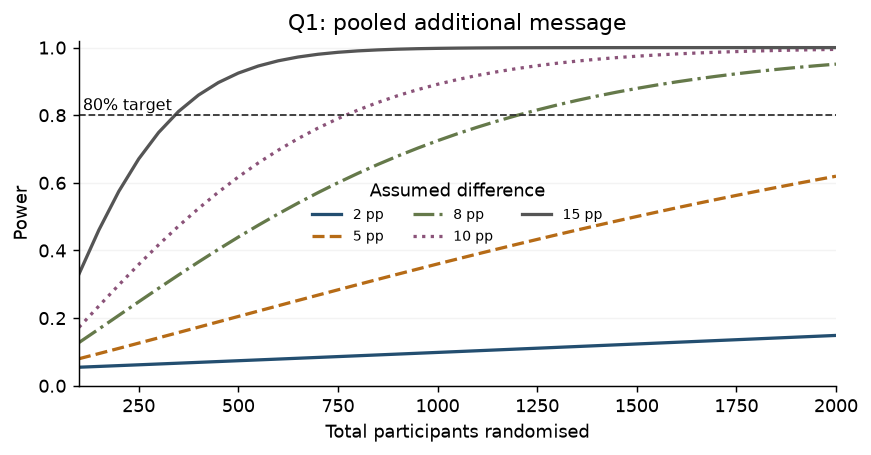

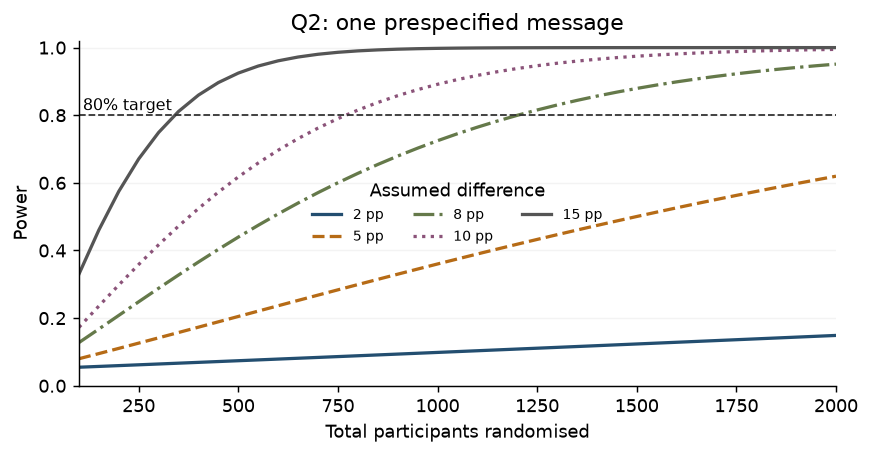

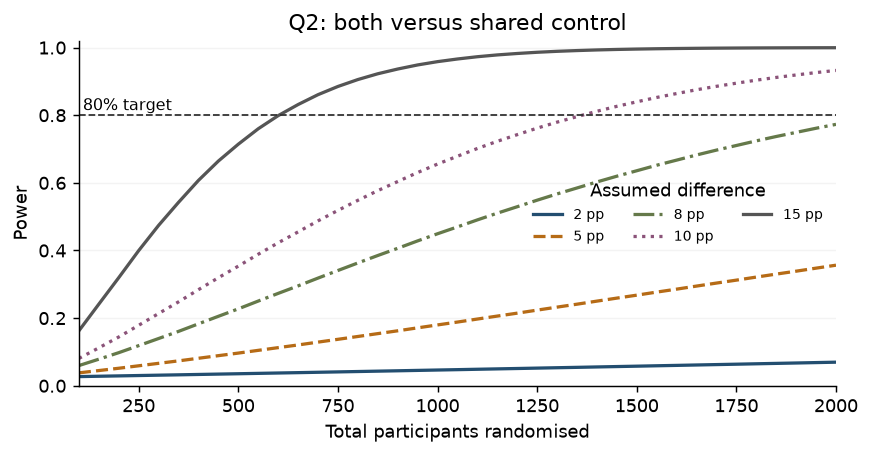

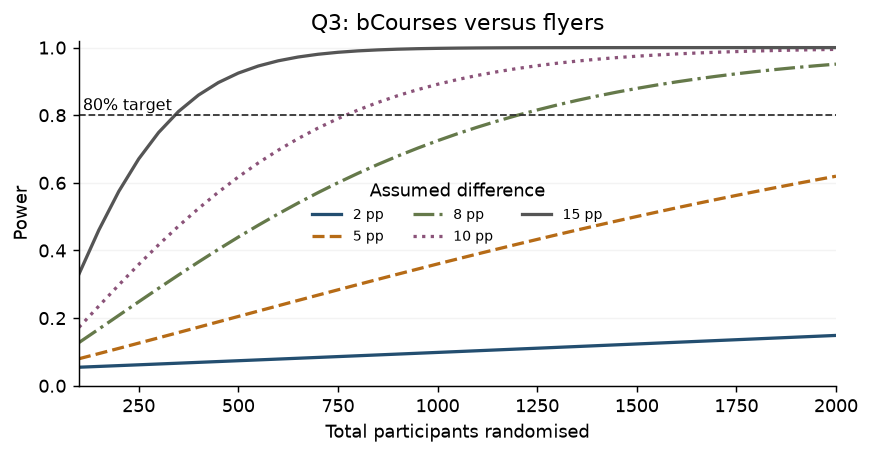

In [6]:
#| echo: false
designs = ['Q1: pooled additional message',
           'Q2: one prespecified message',
           'Q2: both versus shared control',
           'Q3: bCourses versus flyers']
lifts = [.02, .05, .08, .10, .15]
power_rows = [{'Design': d, 'N': int(n), 'Lift': lift,
               'Power': design_power(int(n), lift, d)}
              for d in designs for lift in lifts
              for n in np.arange(100, 2001, 50)]
power_curves = pd.DataFrame(power_rows)
power_curves.to_csv(OUT / 'power_curves.csv', index=False)
for k, design in enumerate(designs):
    fig, ax = plt.subplots(figsize=(6.8, 3.6))
    for lift, color, style in zip(lifts, COLORS, ['-', '--', '-.', ':', '-']):
        line = power_curves[(power_curves.Design == design)
                            & (power_curves.Lift == lift)]
        ax.plot(line.N, line.Power, color=color, ls=style, lw=1.8,
                label=f'{100*lift:g} pp')
    ax.axhline(.8, color='#333333', ls='--', lw=1)
    ax.text(110, .815, '80% target', fontsize=9)
    ax.set(xlabel='Total participants randomised', ylabel='Power',
           title=design, ylim=(0, 1.02), xlim=(100, 2000))
    ax.legend(title='Assumed difference', ncol=3, frameon=False, fontsize=8)
    ax.grid(axis='y', alpha=.15)
    fig.tight_layout()
    fig.savefig(OUT / f'power_{k+1}.png', dpi=220)
    plt.show()

### 3.2 Which allocation answers each question?
**1. Either extra message versus control:** put half in control and half in a pooled message arm, split equally between channels: **1,000 / 500 / 500** at $N=2,000$. This estimates an equal-mixture policy, using contrast $(-1,1/2,1/2)$. The plot assumes equal lifts from both messages. A lift from only one is diluted by half; opposite-signed effects can cancel, so pooling is not an omnibus test that either channel has any effect.

**2. A specific message versus control:** if the channel is chosen in advance, use **1,000 / 1,000 / 0**, or the equivalent for flyers. To compare both messages with a shared control, use approximately $\sqrt{2}:1:1$, or **828 / 586 / 586**. More controls help both comparisons. I use Bonferroni $\alpha=0.025$ per comparison; its curve reports the smaller marginal power, not the probability that both tests reject.

**3. bCourses versus flyers:** use **0 / 1,000 / 1,000** for contrast $(0,-1,1)$. The relevant effect is the gap between channels. Here 40% is an assumed bCourses turnout rate, with flyers higher by the plotted gap. A control arm is useful only if comparisons against ordinary email are also needed.

These ratios assume similar variances. For a two-arm comparison, the variance-minimising ratio is $\sqrt{p_1(1-p_1)/[p_0(1-p_0)]}$. With uncertain probabilities near 40-50%, near-balanced allocations are reasonable. Choosing the better-looking channel after seeing the data would not be a prespecified comparison.

In [7]:
#| echo: false
at_max = power_curves[power_curves.N == 2000].pivot(
    index='Design', columns='Lift', values='Power').reset_index()
at_max.columns = ['Design'] + [f'{int(x*100)} pp' for x in at_max.columns[1:]]
show_table(at_max, 3)

| Design                         | 2 pp   | 5 pp   | 8 pp   | 10 pp   | 15 pp   |
|:-------------------------------|:-------|:-------|:-------|:--------|:--------|
| Q1: pooled additional message  | 0.149  | 0.620  | 0.951  | 0.995   | 1.000   |
| Q2: both versus shared control | 0.070  | 0.357  | 0.773  | 0.932   | 1.000   |
| Q2: one prespecified message   | 0.149  | 0.620  | 0.951  | 0.995   | 1.000   |
| Q3: bCourses versus flyers     | 0.149  | 0.620  | 0.951  | 0.995   | 1.000   |

### 3.3 Minimise exposure
Maximum power and minimum exposure are different objectives. For Q1 and Q2, I use all 2,000 available participants and search for the smallest active-arm total reaching 80% power, keeping the remaining students in control. For Q3, everyone in the comparison receives an extra message, so I search for the smallest near-balanced sample. These are optima within the stated allocations and approximation.

In [8]:
def minimum_exposure(lift, design, maximum=2000, target=.8):
    if design == designs[3]:
        for total in range(2, maximum+1):
            n = allocation(total, [0, .5, .5])
            p = contrast_power(n, [.4, .4, .4+lift], [0, -1, 1])
            if p >= target:
                return n, p
    else:
        step = 1 if design == designs[1] else 2
        for exposed in range(step, maximum, step):
            if design == designs[0]:
                n = np.array([maximum-exposed, exposed//2, exposed//2])
                p = contrast_power(n, [.4, .4+lift, .4+lift], [-1, .5, .5])
            elif design == designs[1]:
                n = np.array([maximum-exposed, exposed, 0])
                p = contrast_power(n, [.4, .4+lift, .4], [-1, 1, 0])
            else:
                n = np.array([maximum-exposed, exposed//2, exposed//2])
                p = min(contrast_power(n, [.4, .4+lift, .4+lift], c, .025)
                        for c in ([-1, 1, 0], [-1, 0, 1]))
            if p >= target:
                return n, p
    return None, None

exposure_rows = []
for design in designs:
    for lift in lifts:
        n, power = minimum_exposure(lift, design)
        exposure_rows.append({
            'Design': design, 'Gap (pp)': int(100*lift),
            'C / B / F': ('Not feasible' if n is None
                           else ' / '.join(map(str, n))),
            'Exposed': (None if n is None else int(n[1]+n[2])),
            'Power': power})
exposure = pd.DataFrame(exposure_rows)
exposure.to_csv(OUT / 'minimum_exposure.csv', index=False)

selected = exposure[exposure['Gap (pp)'] == 10].drop(columns='Gap (pp)').copy()
selected['Design'] = ['Pooled', 'Chosen message', 'Both vs control', 'Head-to-head']
show_table(selected, 3)

| Design          | C / B / F        | Exposed   | Power   |
|:----------------|:-----------------|:----------|:--------|
| Pooled          | 1780 / 110 / 110 | 220       | 0.801   |
| Chosen message  | 1780 / 220 / 0   | 220       | 0.801   |
| Both vs control | 1434 / 283 / 283 | 566       | 0.801   |
| Head-to-head    | 0 / 385 / 385    | 770       | 0.800   |

The table uses a 10-point gap and reports **control / bCourses / flyers**. All five gaps are saved in `outputs/minimum_exposure.csv`. A five-point gap cannot reach 80% power within 2,000, even with a favourable allocation. In practice I would add a margin above these minimums because effect sizes and normal approximations are uncertain.

### 3.4 Simulation check and practical limits
I check the selected designs with 50,000 binomial simulations and a pooled two-proportion z-test, reusing controls for the two-comparison design. The table compares approximate power with simulated marginal power and shows the null family-wise rejection rate.

In [9]:
#| echo: false
def simulate_design(counts, probabilities, comparisons, alpha=.05,
                    repetitions=50000, seed=SEED+1):
    rng = np.random.default_rng(seed)
    n = np.asarray(counts)
    successes = rng.binomial(n, probabilities, size=(repetitions, 3))
    rejections = []
    for control, treatment in comparisons:
        pooled = ((successes[:, control] + successes[:, treatment])
                  / (n[control]+n[treatment]))
        se = np.sqrt(pooled * (1-pooled)
                     * (1/n[control]+1/n[treatment]))
        difference = (successes[:, treatment]/n[treatment]
                      - successes[:, control]/n[control])
        statistic = np.divide(difference, se, out=np.zeros_like(se), where=se>0)
        rejections.append(np.abs(statistic) > norm.ppf(1-alpha/2))
    return np.column_stack(rejections)

simulation_rows = []
for design in designs:
    n, planned = minimum_exposure(.10, design)
    if design == designs[0]:
        # Equal-effect active arms aggregate to one binomial outcome.
        n_sim = [n[0], n[1]+n[2], 0]
        p_sim, comparisons, alpha = [.4, .5, .4], [(0, 1)], .05
    elif design == designs[1]:
        n_sim, p_sim, comparisons, alpha = n, [.4, .5, .4], [(0, 1)], .05
    elif design == designs[2]:
        n_sim, p_sim = n, [.4, .5, .5]
        comparisons, alpha = [(0, 1), (0, 2)], .025
    else:
        n_sim, p_sim, comparisons, alpha = n, [.4, .4, .5], [(1, 2)], .05
    alt = simulate_design(n_sim, p_sim, comparisons, alpha)
    null = simulate_design(n_sim, [.4, .4, .4], comparisons, alpha,
                           seed=SEED+2)
    simulation_rows.append({'Design': design, 'Planning power': planned,
                            'Simulated min marginal power': alt.mean(axis=0).min(),
                            'Simulated null family-wise error': null.any(axis=1).mean()})
simulation = pd.DataFrame(simulation_rows)
compact = simulation.copy()
compact.columns = ['Design', 'Approx. power', 'Sim. power', 'Null FWER']
compact['Design'] = ['Pooled', 'Chosen message', 'Both vs control', 'Head-to-head']
show_table(compact, 3)
simulation.to_csv(OUT / 'simulation_check.csv', index=False)
assert simulation['Simulated null family-wise error'].max() < .06
assert np.all(np.abs(simulation['Planning power']
                     - simulation['Simulated min marginal power']) < .03)
assert abs(contrast_power([1000,1000,0], [.4,.4,.4], [-1,1,0])-.05) < 1e-10
assert contrast_power([1000,1000,0], [.4,.5,.4], [-1,1,0]) > .99
assert design_power(2000, .10, designs[0]) > design_power(500, .10, designs[0])

| Design          | Approx. power   | Sim. power   | Null FWER   |
|:----------------|:----------------|:-------------|:------------|
| Pooled          | 0.801           | 0.808        | 0.050       |
| Chosen message  | 0.801           | 0.808        | 0.050       |
| Both vs control | 0.801           | 0.806        | 0.050       |
| Head-to-head    | 0.800           | 0.797        | 0.052       |

The simulation agrees closely with the approximation. The design should follow the decision: whether to send an extra message, whether a chosen channel beats email, or which channel performs better. Real flyers and class announcements are shared exposures, so individual randomisation may not be feasible. A clustered design would need a new power calculation based on cluster counts, sizes and within-cluster correlation.

## References

- Dekker, I., Luberti, M., & Stam, J. (2023). Effects of supplemental instruction on grades, mental well-being, and belonging: A field experiment. *Learning and Instruction, 87*, 101805. https://doi.org/10.1016/j.learninstruc.2023.101805. Methods: sections 2.1-2.5; grade model: section 3.3 and Table 5.
- Preregistration: https://osf.io/96zp4/, especially response q7 on individual randomisation.
- Instructor starter and data: https://github.com/info-241/problem-set-2-starter, commit `f436fb30a7e5ee52094d140b92787207a83734ee`.
- INFO 241 Unit 3 lecture slides, design grammar.